# Harmonised dataset: overview

`urbanheat harmonize` turns Member 1's 422 hyperspectral + Landsat pairs (EMIT, EnMAP, Hyperion) into one dataset:

- **one band set**: the 10 nm wavelengths every sensor covers (122 bands, 460–2340 nm)
- **one pixel size**: 60 m (30 m pairs are averaged 2×2 over clear pixels)
- **inputs**: hyperspectral, Landsat bands + indices, elevation / slope / built-up share, thermal context, ERA5 weather
- **target**: Landsat LST (°C), as absolute value or as anomaly (pixel minus the pair's median)

Format: `docs/CONTRACTS.md` section 1. Read with `urbanheat.data.dataset.PatchDataset` and `load_pixels`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio
from pathlib import Path
from urbanheat.config import load_config

cfg = load_config()                       # configs/default.yaml + your configs/local.yaml
plt.rcParams["figure.dpi"] = 90

import h5py, json
from urbanheat.data.dataset import PatchDataset, load_pixels

H5 = Path(cfg["data"]["processed_dir"]) / f"urbanheat_v{cfg['harmonize']['version']}.h5"
with h5py.File(H5) as f:
    wl = f.attrs["wavelengths_nm"][:]
    inputs = json.loads(f.attrs["inputs"])
    pairs = pd.DataFrame([dict(pair_id=k, **{a: g.attrs[a] for a in ["sensor", "split", "climate_group", "n_valid", "lst_median_c"]})
                          for k, g in f["pairs"].items()])
print(f"{H5.name}: {H5.stat().st_size / 1e9:.2f} GB, {len(pairs)} pairs, {len(wl)} bands")
print("inputs:", inputs)

urbanheat_v1.h5: 2.21 GB, 422 pairs, 122 bands
inputs: {'ls': ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'NDVI', 'NDBI', 'MNDWI'], 'env': ['elevation_m', 'slope_deg', 'built_share'], 'met': ['air_temp_c', 'rel_humidity', 'wind_speed_kmh', 'solar_rad_wm2', 'cloud_cover_pct', 'air_temp_prev24h_c'], 'thermal': ['lst_context_c']}


## Pairs and valid pixels per sensor and split

The split is Member 1's, **by location**: test cities are never seen in training.

In [2]:
t = pairs.groupby(["sensor", "split"]).agg(pairs=("pair_id", "size"), valid_px=("n_valid", "sum")).unstack(fill_value=0)
t.loc["total"] = t.sum()
t

pairs           valid_px                 
split     test train val     test    train     val
sensor                                            
EMIT        29   202  27   424783  3020973  425964
ENMAP        6    21   4    88029   300373   57936
HYPERION    21    98  14   235243  1015223  151470
total       56   321  45   748055  4336569  635370

In [3]:
pd.crosstab(pairs.climate_group, [pairs.sensor], margins=True)

sensor,EMIT,ENMAP,HYPERION,All
climate_group,,,,
arid,0,0,41,41
cold,0,0,18,18
temperate,0,0,53,53
tropical,258,31,21,310
All,258,31,133,422


## Common wavelength grid

Gaps are the water-vapour absorption regions and places where at least one sensor has no band.

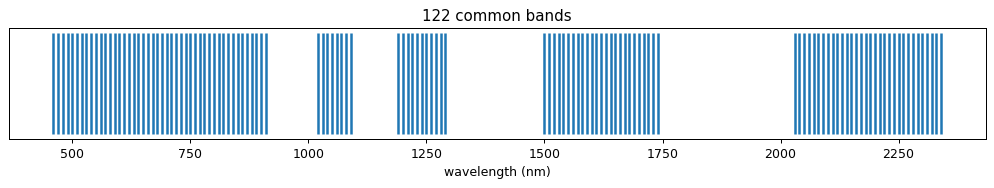

In [4]:
fig, ax = plt.subplots(figsize=(14, 1.6))
ax.vlines(wl, 0, 1, lw=2); ax.set_yticks([]); ax.set_xlabel("wavelength (nm)")
ax.set_title(f"{len(wl)} common bands"); plt.show()

## Do the sensors agree after harmonising?

Median spectrum of built-up and tree pixels per sensor (from the pixel table, all cities). Shapes should match;
levels differ a little because the sensors are calibrated differently (Hyperion reads lower in the SWIR) and the
cities differ. The model also gets the sensor as an input.

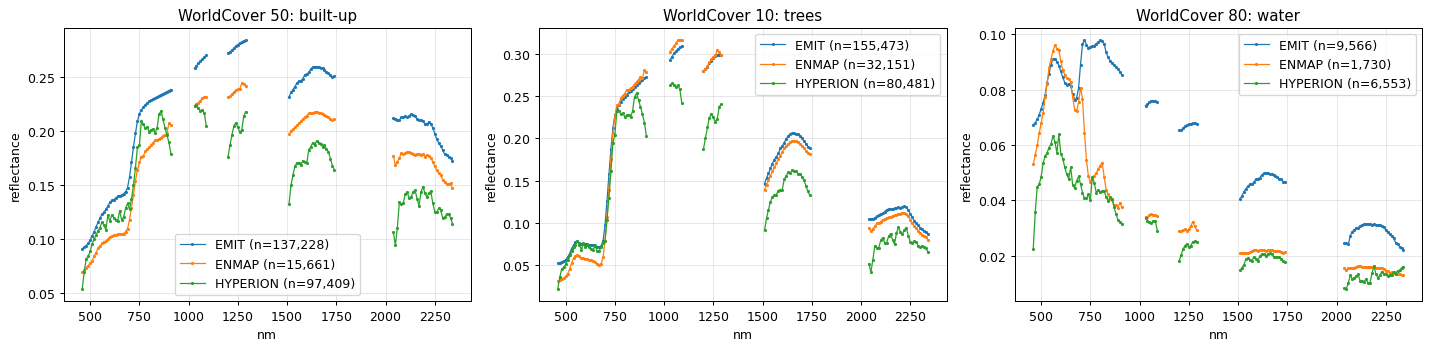

In [5]:
px = load_pixels(H5)
px["sensor"] = np.array([p.split("_")[0] for p in px["pair_id"]])
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (code, name) in zip(ax, [(50, "built-up"), (10, "trees"), (80, "water")]):
    for sensor in ["EMIT", "ENMAP", "HYPERION"]:
        m = (px["landcover"] == code) & (px["sensor"] == sensor)
        if m.sum() > 50:
            spec = np.median(px["hs"][m], axis=0)
            a.plot(wl, np.where(np.r_[True, np.diff(wl) <= 10], spec, np.nan), ".-", ms=3, lw=1, label=f"{sensor} (n={m.sum():,})")
    a.set_title(f"WorldCover {code}: {name}"); a.set_xlabel("nm"); a.set_ylabel("reflectance"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Where does the temperature variation come from?

Absolute LST mixes two things: **how hot the day / climate was** (same for the whole scene) and **which parts of
the city are hotter** (the surface). Only the second can be changed by greening or cool roofs, so the main target is
the anomaly.

train LST variance: total 67.5 °C², within-scene 7.8 °C² (12%) -> between scenes 88%


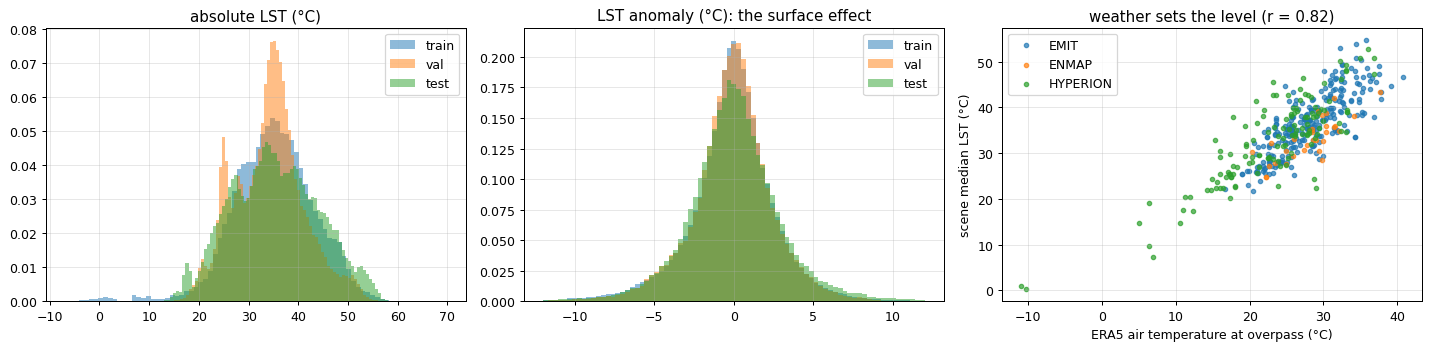

In [6]:
tr = px["split"] == "train"
total, within = px["lst_c"][tr].var(), px["lst_anom"][tr].var()
print(f"train LST variance: total {total:.1f} °C², within-scene {within:.1f} °C² ({within / total:.0%})"
      f" -> between scenes {1 - within / total:.0%}")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for s, col in zip(["train", "val", "test"], ["tab:blue", "tab:orange", "tab:green"]):
    m = px["split"] == s
    ax[0].hist(px["lst_c"][m], bins=80, alpha=.5, density=True, color=col, label=s)
    ax[1].hist(px["lst_anom"][m], bins=np.linspace(-12, 12, 80), alpha=.5, density=True, color=col, label=s)
ax[0].set_title("absolute LST (°C)"); ax[1].set_title("LST anomaly (°C): the surface effect")
with h5py.File(H5) as f:
    air = np.array([f["pairs"][p]["met"][0] for p in pairs.pair_id])
for sensor in ["EMIT", "ENMAP", "HYPERION"]:
    m = pairs.sensor.to_numpy() == sensor
    ax[2].scatter(air[m], pairs.lst_median_c[m], s=12, alpha=.7, label=sensor)
ax[2].set_xlabel("ERA5 air temperature at overpass (°C)"); ax[2].set_ylabel("scene median LST (°C)")
ax[2].set_title(f"weather sets the level (r = {np.corrcoef(air, pairs.lst_median_c)[0, 1]:.2f})")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## One training patch through the loader

What a model sees: 32 × 32 pixels at 60 m (≈ 1.9 km), normalised with train statistics, invalid pixels set to 0.

{'train': 11621, 'val': 561, 'test': 617} patches
{'hs': (122, 32, 32), 'ls': (9, 32, 32), 'env': (3, 32, 32), 'thermal': (1, 32, 32), 'met': (6,), 'y': (32, 32), 'mask': (32, 32), 'sensor': 0}


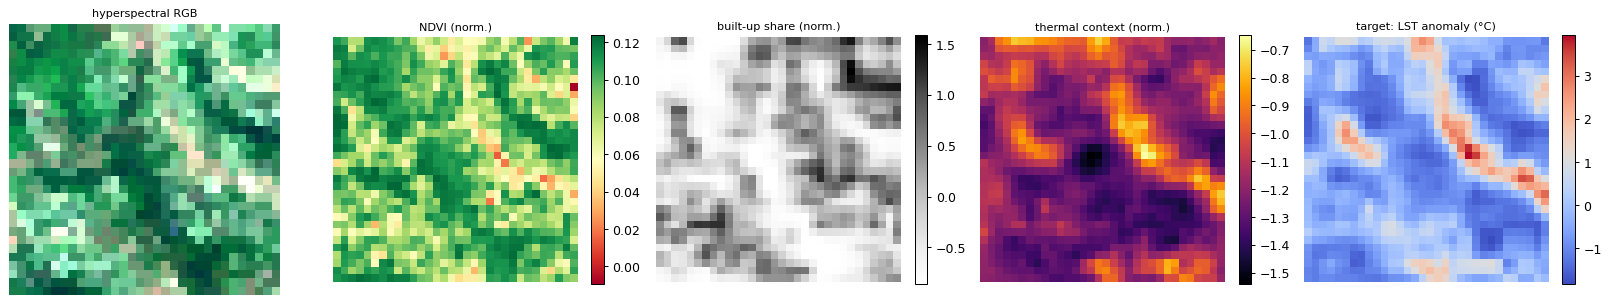

In [7]:
ds = PatchDataset(H5, "train")
print({s: len(PatchDataset(H5, s)) for s in ["train", "val", "test"]}, "patches")
b = ds[len(ds) // 3]
print({k: getattr(v, "shape", v) for k, v in b.items()})
rgb = np.dstack([b["hs"][np.argmin(abs(wl - w))] for w in (650, 550, 470)])
rgb = np.clip((rgb - np.percentile(rgb, 2)) / (np.percentile(rgb, 98) - np.percentile(rgb, 2)), 0, 1)
fig, ax = plt.subplots(1, 5, figsize=(18, 3.6))
for a, img, t, cm in [(ax[0], rgb, "hyperspectral RGB", None), (ax[1], b["ls"][6], "NDVI (norm.)", "RdYlGn"),
                      (ax[2], b["env"][2], "built-up share (norm.)", "Greys"), (ax[3], b["thermal"][0], "thermal context (norm.)", "inferno"),
                      (ax[4], np.where(b["mask"], b["y"], np.nan), "target: LST anomaly (°C)", "coolwarm")]:
    im = a.imshow(img, cmap=cm); a.set_title(t, fontsize=9); a.axis("off")
    if cm: plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

## Summary

- 422 pairs, 122 common bands, 60 m, about 5.7 million valid pixels; 11.6 k / 0.56 k / 0.62 k patches for train / val / test.
- About 88 % of the LST variance is between scenes (weather, climate) and 12 % within cities (spread ≈ 2.8 °C).
  That within-city part is what mitigation can change, so models predict the **anomaly**.
- After harmonising, the sensors' spectra have the same shapes; remaining level differences (e.g. Hyperion SWIR)
  are known calibration differences and the sensor is a model input.
- **Next:** baselines (RF / XGBoost) and the factor analysis (which surface factors drive the anomaly).